# Visualizations
### Where airport workers live

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from src.config import AIRPORTS, OUTPUT_DIR, PROCESSED_DIR

# figures in the midterm report vs extras kept in the repo
for folder in ["midterm_submission", "extra"]:
    os.makedirs(f"{OUTPUT_DIR}/{folder}", exist_ok=True)

In [2]:
# FIPS to county mapping
COUNTY_NAMES = {
    "001": "Alameda",
    "013": "Contra Costa",
    "041": "Marin",
    "055": "Napa",
    "075": "San Francisco",
    "081": "San Mateo",
    "085": "Santa Clara",
    "095": "Solano",
    "097": "Sonoma",
}
AIRPORT_COUNTY = {"SFO": "San Mateo", "OAK": "Alameda", "SJC": "Santa Clara"}

In [3]:
def worker_shares_by_county():
    """percent of each airport's bay area workers living in each county, plus worker totals."""
    workers = pd.read_csv(f"{PROCESSED_DIR}/airport_workers_by_tract.csv", dtype={"GEOID": str})
    workers["county"] = workers["GEOID"].str[2:5].map(COUNTY_NAMES)
    # code is airport code
    counts = workers.pivot_table(index="county", columns="code", values="S000", aggfunc="sum", fill_value=0)
    counts = counts.loc[counts.sum(axis=1).sort_values().index]
    # return each county's percent for each airport, total worker ct for each airport from LODES
    return counts.div(counts.sum()) * 100, counts.sum()
worker_shares_by_county()

(code                 OAK        SFO        SJC
 county                                        
 Napa            0.423867   0.592478   0.229768
 Marin           0.945549   1.554182   0.638244
 Sonoma          1.891099   1.322342   1.097779
 Solano          4.336485   3.941267   1.736022
 Contra Costa   15.487447   9.136184   6.152668
 San Francisco   6.847082  20.032629   3.267807
 Santa Clara     7.694816   8.560879  65.892264
 San Mateo       8.346919  35.188047   5.182538
 Alameda        54.026736  19.671990  15.802910,
 code
 OAK     3067
 SFO    11646
 SJC     3917
 dtype: int64)

In [4]:
def plot_worker_home_counties():
    shares, totals = worker_shares_by_county()
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.5), sharey=True, sharex=True)

    for ax, airport in zip(axes, AIRPORTS):
        # highlight the airport's own county (week 9: one color per series, highlight only the bar of interest)
        # same county order in every panel so they compare across airports
        colors = ["#E69F00" if c == AIRPORT_COUNTY[airport] else "#0072B2" for c in shares.index]
        ax.barh(shares.index, shares[airport], color=colors)
        ax.set_title(f"{airport} ({totals[airport]:,} Bay Area workers)", fontsize=11)
        ax.set_xlabel("% of airport's Bay Area workers")
        ax.set_xlim(0, 75)
        ax.spines[["top", "right"]].set_visible(False)
        for county in shares[airport].nlargest(3).index:
            ax.text(shares.loc[county, airport] + 1, county, f"{shares.loc[county, airport]:.0f}%", va="center", fontsize=9)

    fig.suptitle("Where airport workers live: OAK and SJC primarily reside locally, SFO from across the region", fontsize=12)
    caption = "Where each airport's Bay Area workers live, by home county, from 2023 LODES home-to-work data."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(f"{OUTPUT_DIR}/midterm_submission/airport_worker_home_counties.png", dpi=300)
    return fig

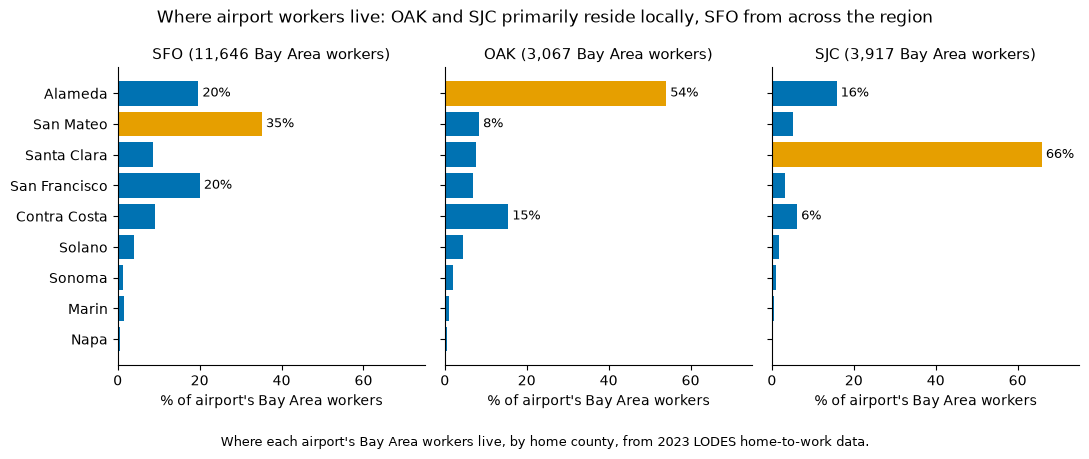

In [5]:
fig = plot_worker_home_counties()

### Transit vs car

In [6]:
'''
We are using the color scheme recommended in the Week 9 plotly notebook. Verbatim, it says:
Blue and orange for every comparison of two groups, with gray for anything neutral.  This pair from the Okabe-Ito palette stays distinguishable 
for the most common types of color blindness (Wilke, Ch. 19). Each chart's legend says which group is which. Example 4 draws the typical week in gray."
'''
WINDOW_COLORS = {"4-5 am": "#0072B2", "7-8 am": "#E69F00"}


def transit_vs_drive():
    """transit time over drive time for each tract and airport, and the percent of tracts with no transit trip within 3 h."""
    compare = pd.read_csv(f"{PROCESSED_DIR}/transit_vs_drive.csv", dtype={"GEOID": str})
    # blank transit_min = no trip within 3 h
    no_trip = compare.groupby(["window", "code"])["transit_min"].apply(lambda t: t.isna().mean() * 100).round(0)
    return compare.dropna(subset=["transit_min"]), no_trip
transit_vs_drive()[1]

window  code
4-5 am  OAK     32.0
        SFO     30.0
        SJC     37.0
7-8 am  OAK     19.0
        SFO     19.0
        SJC     27.0
Name: transit_min, dtype: float64

In [7]:
def plot_transit_vs_drive():
    compare, no_trip = transit_vs_drive()
    fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True, sharex=True)
    bins = [b / 2 for b in range(0, 21)]  # 0 to 10 in half steps

    for row, (window, color) in zip(axes, WINDOW_COLORS.items()):
        for ax, airport in zip(row, AIRPORTS):
            rows = (compare["code"] == airport) & (compare["window"] == window)
            # cap at 10x so a few far tracts don't stretch the axis
            ratio = compare.loc[rows, "transit_over_drive"].clip(upper=10)
            ax.hist(ratio, bins=bins, color=color)
            ax.set_ylim(0, 600)
            ax.axvline(ratio.median(), color="#333333", linestyle="--", linewidth=1)
            ax.text(ratio.median() + 0.2, 550, f"median {ratio.median():.1f}x", fontsize=9, color="#333333")
            # lots of tracts with no transit trip aren't in the histogram
            ax.text(0.97, 0.78, f"{no_trip[(window, airport)]:.0f}% no trip within 3 h", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#777777")
            ax.spines[["top", "right"]].set_visible(False)
        row[0].set_ylabel(f"leave {window}\nnumber of tracts")
    for ax, airport in zip(axes[0], AIRPORTS):
        ax.set_title(airport, fontsize=11)
    for ax in axes[1]:
        ax.set_xlabel("transit time / drive time")

    fig.suptitle("Transit takes 3-4 times as long as driving to the airport, and longer for early shifts", fontsize=12)
    caption = "How many times longer the typical transit trip takes than driving w/ no traffic, for every Bay Area tract on Wednesday Oct 28, 2026, from the 511 feed and OpenStreetMap via r5py."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=8)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(f"{OUTPUT_DIR}/midterm_submission/transit_vs_drive.png", dpi=300)
    return fig

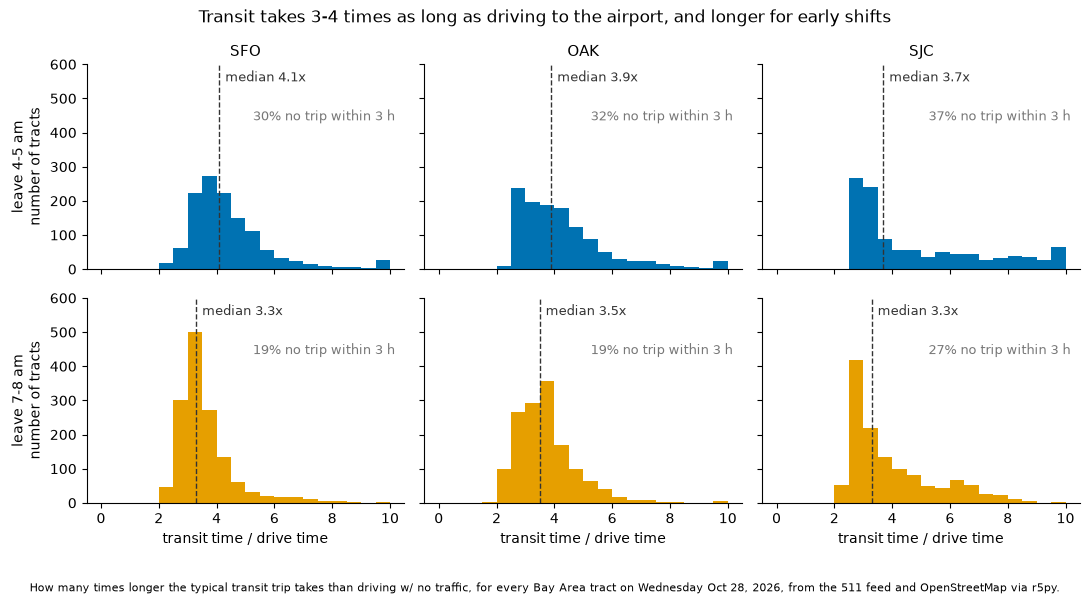

In [8]:
fig = plot_transit_vs_drive()

### Share of workers reaching each airport by 4, 5, 6 and 8 am

In [9]:
DAY_COLORS = {"Wed": "#0072B2", "Sun": "#E69F00"}
DAY_NAMES = {"2026-10-28": "Wed", "2026-11-08": "Sun"}
SHIFT_HOURS = [4, 5, 6, 8]


def reach_by_hour():
    """share of tracts and of each airport's workers with an earliest arrival at or before each shift hour"""
    first = pd.read_csv(f"{PROCESSED_DIR}/transit_earliest_arrival.csv", dtype={"GEOID": str})
    workers = pd.read_csv(f"{PROCESSED_DIR}/airport_workers_by_tract.csv", dtype={"GEOID": str})
    first = first.merge(workers[["GEOID", "code", "S000"]], on=["GEOID", "code"], how="left").fillna({"S000": 0})
    rows = []
    for (day, code), g in first.groupby(["day", "code"]):
        for hour in SHIFT_HOURS:
            by_then = g["arrival_min"] <= hour * 60
            rows.append({"day": DAY_NAMES[day], "code": code, "hour": hour, "tracts": by_then.mean() * 100, "workers": g.loc[by_then, "S000"].sum() / g["S000"].sum() * 100})
    return pd.DataFrame(rows)
reach_by_hour().pivot_table(index=["day", "hour"], columns="code", values=["tracts", "workers"]).round(0)

tracts             workers            
code        OAK   SFO   SJC     OAK   SFO   SJC
day hour                                       
Sun 4       9.0  17.0   2.0    28.0  38.0   4.0
    5      26.0  27.0   2.0    43.0  49.0   4.0
    6      32.0  31.0  17.0    50.0  52.0  20.0
    8      40.0  42.0  43.0    64.0  62.0  62.0
Wed 4       9.0  17.0   1.0    28.0  38.0   3.0
    5      26.0  27.0   3.0    43.0  49.0  12.0
    6      41.0  37.0  29.0    57.0  59.0  53.0
    8      77.0  76.0  73.0    87.0  87.0  88.0

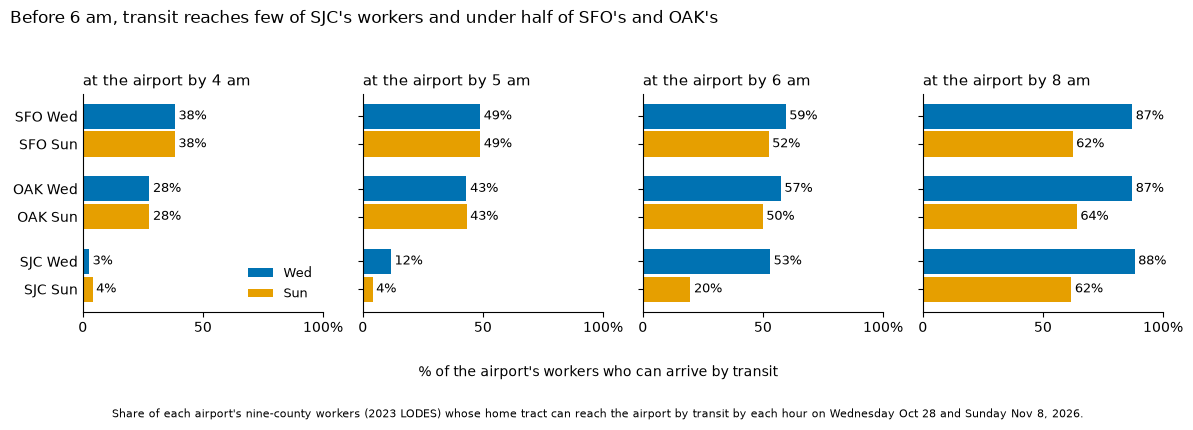

In [10]:
def plot_reach_by_hour():
    reach = reach_by_hour().set_index(["hour", "code", "day"])
    fig, axes = plt.subplots(1, 4, figsize=(12, 4.2), sharey=True)
    for ax, hour in zip(axes, SHIFT_HOURS):
        for i, code in enumerate(AIRPORTS):
            for j, (day, color) in enumerate(DAY_COLORS.items()):
                y = -(i * 2.6 + j)  # SFO on top, Wed bar above Sun bar
                value = reach.loc[(hour, code, day), "workers"]
                ax.barh(y, value, color=color, height=0.9, label=day if (hour == SHIFT_HOURS[0] and i == 0) else None)
                ax.text(value + 1.5, y, f"{value:.0f}%", va="center", fontsize=9)
        ax.set_title(f"at the airport by {hour} am", fontsize=11, loc="left")
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 50, 100], ["0", "50", "100%"])
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_yticks([-(i * 2.6 + j) for i in range(3) for j in range(2)], [f"{code} {day}" for code in AIRPORTS for day in DAY_COLORS])
    axes[0].tick_params(axis="y", length=0)
    axes[0].legend(frameon=False, fontsize=9, loc="lower right")
    fig.supxlabel("% of the airport's workers who can arrive by transit", fontsize=10, y=0.1)
    fig.suptitle("Before 6 am, transit reaches few of SJC's workers and under half of SFO's and OAK's", fontsize=12, x=0.01, ha="left")
    caption = "Share of each airport's nine-county workers (2023 LODES) whose home tract can reach the airport by transit by each hour on Wednesday Oct 28 and Sunday Nov 8, 2026."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=8)
    plt.tight_layout(rect=(0, 0.1, 1, 0.94))
    fig.savefig(f"{OUTPUT_DIR}/midterm_submission/reach_by_hour.png", dpi=300)
    return fig
fig = plot_reach_by_hour()

### Reach within 30, 60 and 90 minutes
Catchment view from the same trip times as the transit vs car chart: share of tracts and of each airport's workers w/ a transit trip of at most 30, 60 or 90 minutes.

In [11]:
def reach_within_minutes(cuts=(30, 60, 90)):
    trips = pd.read_csv(f"{PROCESSED_DIR}/transit_trip_times.csv", dtype={"GEOID": str})
    workers = pd.read_csv(f"{PROCESSED_DIR}/airport_workers_by_tract.csv", dtype={"GEOID": str})[["GEOID", "code", "S000"]]
    trips = trips.merge(workers, on=["GEOID", "code"], how="left").fillna({"S000": 0})
    rows = []
    for (window, code), group in trips.groupby(["window", "code"]):
        for cut in cuts:
            ok = group["transit_min"] <= cut
            rows.append({"window": window, "code": code, "within_min": cut, "tracts_pct": round(ok.mean() * 100), "workers_pct": round((ok * group["S000"]).sum() / group["S000"].sum() * 100)})
    table = pd.DataFrame(rows)
    table.to_csv(f"{OUTPUT_DIR}/transit_reach_within_minutes.csv", index=False)
    return table.pivot_table(index=["window", "code"], columns="within_min", values=["tracts_pct", "workers_pct"])

reach_within_minutes()

tracts_pct             workers_pct            
within_min          30    60    90          30    60    90
window code                                               
4-5 am OAK         0.0   3.0  27.0         0.0  17.0  47.0
       SFO         0.0   4.0  20.0         1.0  17.0  46.0
       SJC         0.0   3.0  12.0         0.0  11.0  41.0
7-8 am OAK         0.0  10.0  33.0         0.0  33.0  60.0
       SFO         1.0  17.0  32.0         3.0  45.0  59.0
       SJC         0.0   8.0  24.0         3.0  25.0  59.0

In [12]:
import geopandas as gpd
from matplotlib.patches import Patch

from src.config import COUNTY_FIPS, CRS, RAW_DIR
from src.lodes import download, load_airports

def bay_area_tracts():
    """2020 cartographic tracts (clipped to the shoreline, so the bay shows as water), in our CRS."""
    download("https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_06_tract_500k.zip", f"{RAW_DIR}/ca_tracts_2020_cartographic.zip")
    tracts = gpd.read_file(f"{RAW_DIR}/ca_tracts_2020_cartographic.zip")
    return tracts[tracts["COUNTYFP"].isin(COUNTY_FIPS)].to_crs(CRS)[["GEOID", "COUNTYFP", "geometry"]]

### Earliest transit arrival map

[airports] match airport names: 8,110 -> 3 (TIGER landmark is not an SFO, OAK or SJC airport (k2457))


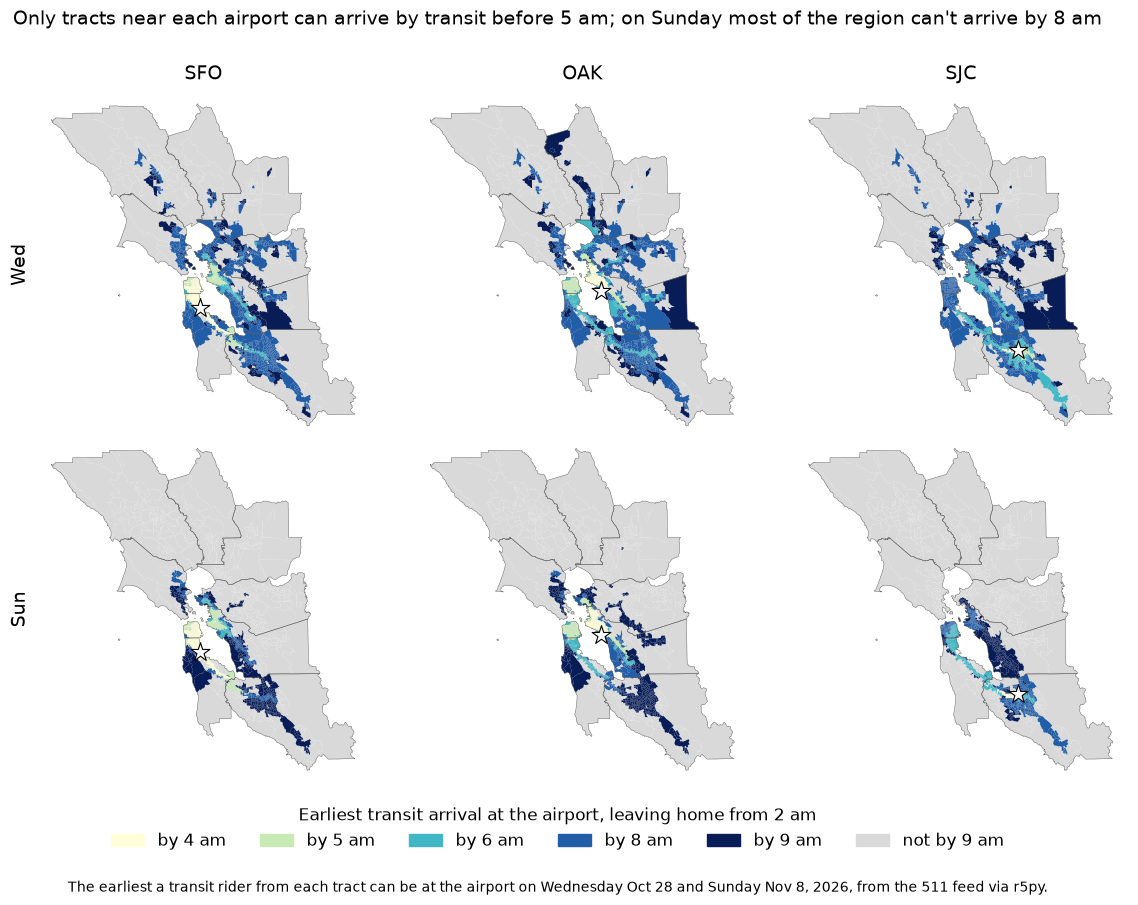

In [13]:
ARRIVAL_BINS = [0, 4 * 60, 5 * 60, 6 * 60, 8 * 60, 9 * 60]
ARRIVAL_LABELS = ["by 4 am", "by 5 am", "by 6 am", "by 8 am", "by 9 am"]


def plot_earliest_arrival():
    first = pd.read_csv(f"{PROCESSED_DIR}/transit_earliest_arrival.csv", dtype={"GEOID": str})
    # classes are the shift start times we care about, not equal intervals
    first["class"] = pd.cut(first["arrival_min"], bins=ARRIVAL_BINS, labels=ARRIVAL_LABELS)
    tracts = bay_area_tracts()
    counties = tracts.dissolve("COUNTYFP")
    airports = load_airports().to_crs(CRS)
    # sequential colorbrewer scale, darker = later arrival (same scale from lab 7)
    colors = plt.get_cmap("YlGnBu", len(ARRIVAL_LABELS))

    fig, axes = plt.subplots(2, 3, figsize=(12, 9))
    for row, (day, name) in zip(axes, DAY_NAMES.items()):
        for ax, airport in zip(row, AIRPORTS):
            panel = tracts.merge(first[(first["day"] == day) & (first["code"] == airport)], on="GEOID")
            panel.plot(ax=ax, color="#d9d9d9")  # gray means no arrival by 9 am
            panel.dropna(subset=["class"]).plot(ax=ax, column="class", cmap=colors, categorical=True, legend=False)
            counties.boundary.plot(ax=ax, color="#555555", linewidth=0.3)
            point = airports.loc[airports["code"] == airport, "geometry"].iloc[0].representative_point()
            ax.scatter(point.x, point.y, marker="*", s=200, color="white", edgecolor="black", linewidth=0.8, zorder=5)
            ax.set_axis_off()
        row[0].text(-0.02, 0.5, name, transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=14)
    for ax, airport in zip(axes[0], AIRPORTS):
        ax.set_title(airport, fontsize=14)

    handles = [Patch(color=colors(k), label=label) for k, label in enumerate(ARRIVAL_LABELS)] + [Patch(color="#d9d9d9", label="not by 9 am")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.04), ncol=6, frameon=False, fontsize=12, title_fontsize=12, title="Earliest transit arrival at the airport, leaving home from 2 am")
    fig.suptitle("Only tracts near each airport can arrive by transit before 5 am; on Sunday most of the region can't arrive by 8 am", fontsize=14, y=0.99)
    caption = "The earliest a transit rider from each tract can be at the airport on Wednesday Oct 28 and Sunday Nov 8, 2026, from the 511 feed via r5py."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=10)
    plt.tight_layout(rect=(0.02, 0.11, 1, 0.97))
    fig.savefig(f"{OUTPUT_DIR}/midterm_submission/earliest_arrival_map.png", dpi=300)
    return fig
fig = plot_earliest_arrival()

### Rideshare fares


In [14]:
import numpy as np

from src.fares import rate_card_fare

COMPONENT_COLORS = {"ride_charge": ("Metered fare", "#0072B2"), "service_fee": ("Service fee", "#56B4E9"), "airport_fee": ("Airport fee", "#E69F00"), "toll": ("Bridge toll", "#D55E00")}


def load_fares():
    """rate card fare for every tract and airport, and the same joined to where airport workers live"""
    fares = rate_card_fare(pd.read_csv(f"{PROCESSED_DIR}/drive_times.csv", dtype={"GEOID": str}, keep_default_na=False))
    fares["county"] = fares["GEOID"].str[2:5].map(COUNTY_NAMES)
    workers = pd.read_csv(f"{PROCESSED_DIR}/airport_workers_by_tract.csv", dtype={"GEOID": str})
    return fares, workers.merge(fares, on=["code", "GEOID"])


fares, worker_fares = load_fares()
fares.groupby("code")["rate_card_fare"].median().round(0)

code
OAK    56.0
SFO    64.0
SJC    82.0
Name: rate_card_fare, dtype: float64

#### Estimated fare from every tract

[airports] match airport names: 8,110 -> 3 (TIGER landmark is not an SFO, OAK or SJC airport (k2457))


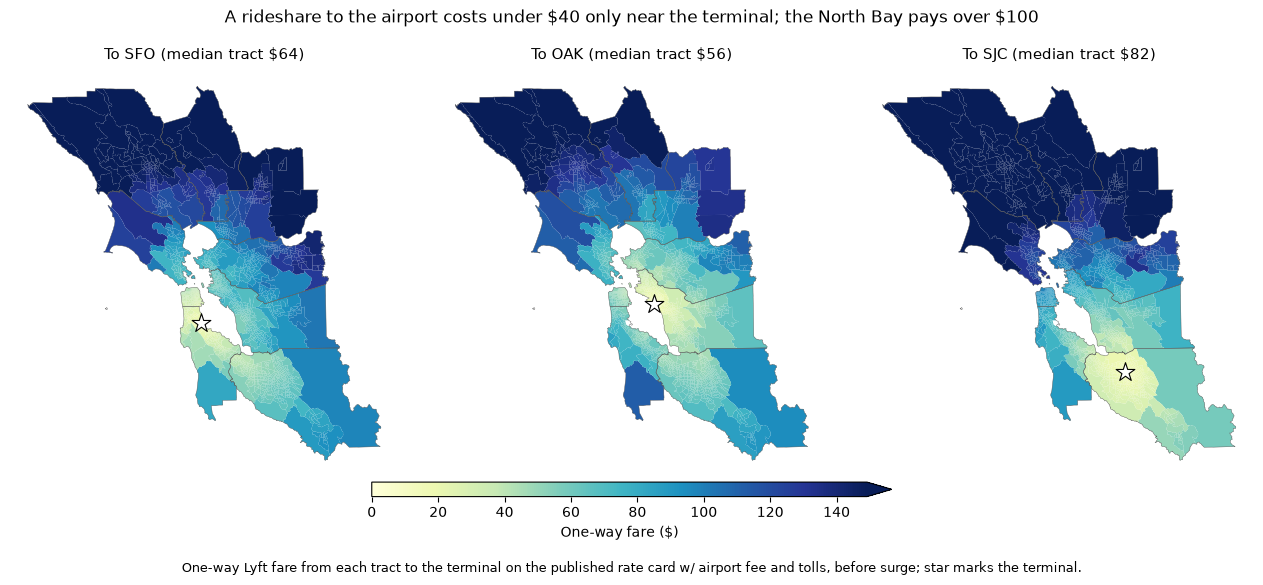

In [15]:
def plot_fare_maps():
    tracts = bay_area_tracts()
    counties = tracts.dissolve("COUNTYFP")
    airports = load_airports().to_crs(CRS)
    gdf = tracts.merge(fares, on="GEOID")
    vmax = gdf["rate_card_fare"].quantile(0.95)
    fig, axes = plt.subplots(1, 3, figsize=(13, 5.8))
    for ax, airport in zip(axes, AIRPORTS):
        trips = gdf[gdf["code"] == airport]
        # sequential colormap, darker = pricier (week 6 lecture, lab 7 choropleths)
        trips.plot(column="rate_card_fare", ax=ax, cmap="YlGnBu", vmin=0, vmax=vmax, linewidth=0)
        counties.boundary.plot(ax=ax, color="#555555", linewidth=0.3)
        point = airports.loc[airports["code"] == airport, "geometry"].iloc[0].representative_point()
        ax.scatter(point.x, point.y, marker="*", s=200, color="white", edgecolor="black", linewidth=0.8, zorder=5)
        ax.set_title(f"To {airport} (median tract ${trips['rate_card_fare'].median():.0f})", fontsize=11)
        ax.set_axis_off()
    fig.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.17, wspace=0.02)
    bar = fig.colorbar(plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.Normalize(0, vmax)), cax=fig.add_axes([0.3, 0.14, 0.4, 0.025]), orientation="horizontal", extend="max")
    bar.set_label("One-way fare ($)")
    fig.suptitle("A rideshare to the airport costs under \\$40 only near the terminal; the North Bay pays over \\$100", fontsize=12)
    caption = "One-way Lyft fare from each tract to the terminal on the published rate card w/ airport fee and tolls, before surge; star marks the terminal."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=9)
    fig.savefig(f"{OUTPUT_DIR}/extra/fare_maps.png", dpi=300)
    return fig
fig = plot_fare_maps()

#### Where the money goes

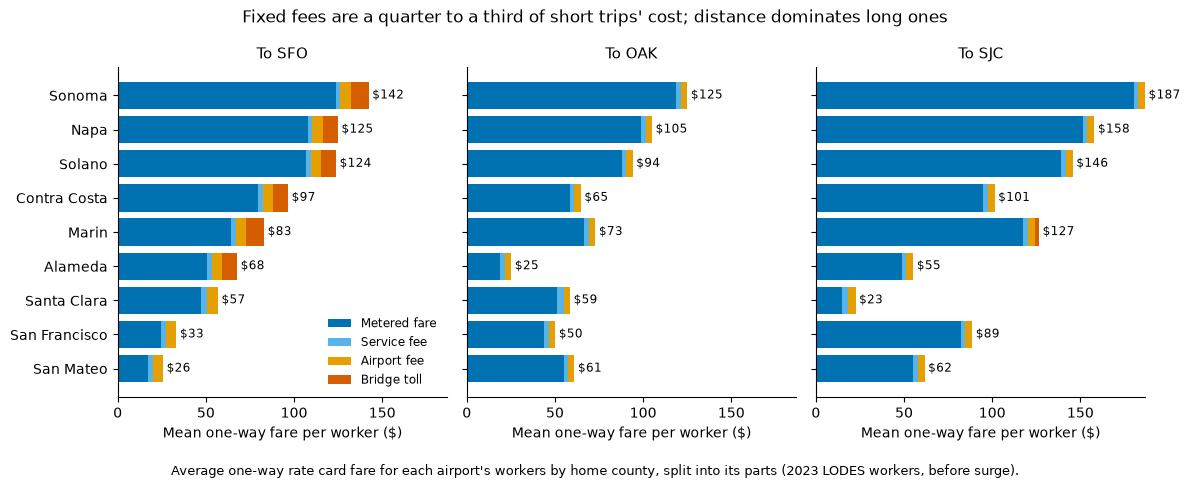

In [16]:
def plot_fare_components():
    # worker-weighted mean of each fare component by home county
    weighted = worker_fares[list(COMPONENT_COLORS)].mul(worker_fares["S000"], axis=0)
    weighted[["code", "county", "S000"]] = worker_fares[["code", "county", "S000"]]
    sums = weighted.groupby(["code", "county"]).sum()
    means = sums[list(COMPONENT_COLORS)].div(sums["S000"], axis=0)
    order = means.loc["SFO"].sum(axis=1).sort_values().index

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), sharey=True, sharex=True)
    for ax, airport in zip(axes, AIRPORTS):
        table = means.loc[airport].reindex(order).fillna(0)
        left = np.zeros(len(table))
        for column, (label, color) in COMPONENT_COLORS.items():
            ax.barh(table.index, table[column], left=left, color=color, label=label)
            left += table[column]
        for county, total in zip(table.index, left):
            ax.text(total + 2, county, f"${total:.0f}", va="center", fontsize=8.5)
        ax.set_title(f"To {airport}", fontsize=11)
        ax.set_xlabel("Mean one-way fare per worker ($)")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, loc="lower right", fontsize=8.5)
    fig.suptitle("Fixed fees are a quarter to a third of short trips' cost; distance dominates long ones", fontsize=12)
    caption = "Average one-way rate card fare for each airport's workers by home county, split into its parts (2023 LODES workers, before surge)."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(f"{OUTPUT_DIR}/midterm_submission/fares_by_county.png", dpi=300)
    return fig
fig = plot_fare_components()

#### Fare against trip distance

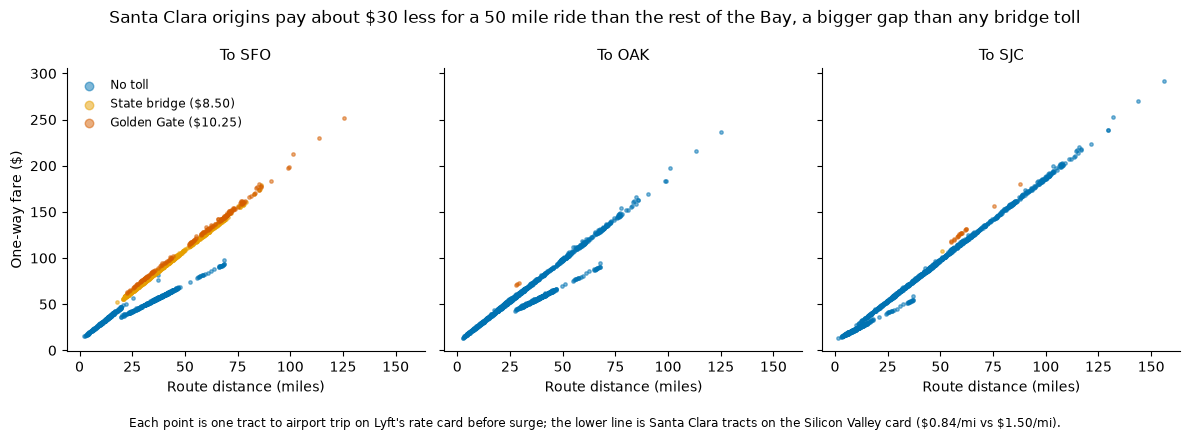

In [17]:
def plot_fare_vs_distance():
    kinds = {"No toll": "#0072B2", "State bridge ($8.50)": "#E69F00", "Golden Gate ($10.25)": "#D55E00"}
    kind = np.select([fares["bridges"].str.contains("golden_gate"), fares["toll"] > 0], ["Golden Gate ($10.25)", "State bridge ($8.50)"], "No toll")
    quotes = pd.read_csv(f"{PROCESSED_DIR}/quoted_fares.csv", dtype={"GEOID": str}).dropna(subset=["price"])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True, sharex=True)
    for ax, airport in zip(axes, AIRPORTS):
        for label, color in kinds.items():
            trips = fares[(fares["code"] == airport) & (kind == label)]
            ax.scatter(trips["miles"], trips["rate_card_fare"], s=6, alpha=0.5, color=color, label=label)
        collected = quotes[quotes["code"] == airport]
        if len(collected):
            ax.scatter(collected["miles"], collected["price"], s=25, marker="x", color="black", label="Collected quote")
        ax.set_title(f"To {airport}", fontsize=11)
        ax.set_xlabel("Route distance (miles)")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("One-way fare ($)")
    axes[0].legend(frameon=False, markerscale=2.5, fontsize=8.5)
    fig.suptitle("Santa Clara origins pay about \\$30 less for a 50 mile ride than the rest of the Bay, a bigger gap than any bridge toll", fontsize=12)
    caption = "Each point is one tract to airport trip on Lyft's rate card before surge; the lower line is Santa Clara tracts on the Silicon Valley card (\\$0.84/mi vs \\$1.50/mi)."
    fig.text(0.5, 0.01, caption, ha="center", fontsize=8.5)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(f"{OUTPUT_DIR}/extra/fare_vs_distance.png", dpi=300)
    return fig
fig = plot_fare_vs_distance()